# T 측정 녹음 전 점검 — 재생 스피커 수와 B0 바닥 (Step8d)

> 2026-10-28 · 기존 장치 녹음만 사용 · 방향 [`doa/doa_stream.py`](../doa/doa_stream.py) (MCU와 같은 계산의 PC 기준 구현) · B0 [`harmonic/score.py`](../harmonic/score.py) · 커널: `Tools/.venv`
> **먼저 볼 곳: 맨 끝 [결론부](#결론부) (그림 2장).** 그 위의 0 ~ B 절은 근거 요약과 숫자 출력이라, 의문이 생길 때만 읽으면 된다.

**왜 하나:** Step8d는 드론 소리를 2 dB씩 줄여 틀어서(`51_T_fpv_steps.wav`) 판정·방향이 무너지는 SNR, 즉 탐지거리 식의 **T**를 잴 계획이다 ([snr_T.ipynb](snr_T.ipynb)). 그 녹음 전에 두 가지가 측정을 망칠 수 있는지 기존 녹음으로 본다.

| 질문 | 왜 걱정인가 |
|---|---|
| **A. 재생 파일이 모노라 노트북 스피커 두 개에서 같이 나오면 방향 결과가 망가지나?** | T(방향)가 "소리가 작아서"가 아니라 "소리가 두 군데서 와서" 무너질 수 있다 |
| **B. B0 판정이 드론이 없는 녹음에서 얼마나 "드론"이라고 하나?** | 성공률이 그 비율 밑으로 안 내려가면 "성공률 50 %가 되는 SNR"을 못 찾는다 |

| A에 쓰는 녹음 | 스피커 | 거리·방위 | 배경 (방향 계산용) | 날짜 |
|---|---|---|---|---|
| `speaker_10min` (`20_drones_10min.wav` 재생) | **두 개** (모노 파일) | 기록 없음 | `quiet_10min` 앞 60 s | 10-16 |
| `doa_az000` ~ `doa_az330` (`21_doa_left_100s.wav` 재생) | **왼쪽 하나** | 1 m, 12방향 | `doa_bg` (에어컨) | 10-18 |

**한계 (A):** 두 녹음은 스피커 수만 다른 것이 아니다 — 거리, 날짜, 배경도 다르다. **변수 하나만 바꾼 비교가 아니다.** 깔끔한 확인은 같은 자리에서 모노·왼쪽만 두 번 녹음하는 것이다 (보드 필요).

In [1]:
import os, sys, argparse
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.signal import butter, sosfiltfilt
_have = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ("Malgun Gothic", "AppleGothic", "NanumGothic") if f in _have), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
sys.path[:0] = [os.path.abspath(".."), os.path.abspath("../doa")]
import harmonic.score as hs
import doa_stream as ds
import gcc_phat as g

FS = 12500
DUMPS, PBK = "../dumps/stream", "../../DataSet/_playback"
ap = argparse.ArgumentParser(); ds.add_args(ap); A = ap.parse_args([])       # 보드와 같은 설정
POS, D = ds.positions()
MAX_LAG = D / g.SOUND_SPEED * FS + 1.0
def env_db(sig, fs, win=0.5):
    sos = butter(4, [300, 3000], btype="band", fs=fs, output="sos"); b = sosfiltfilt(sos, sig); h = int(win * fs); m = len(b) // h
    return 10 * np.log10(2 * np.mean(b[:m * h].reshape(m, h) ** 2, axis=1) + 1e-20)
def wrap(a): return (np.asarray(a) + 180) % 360 - 180
col = lambda R, k: np.array([r[k] for r in R])
print(f"마이크 간격 {D * 1000:.0f} mm, 최대 지연 ±{MAX_LAG - 1:.2f} 샘플, 유효 조건: 피크 ≥ {A.min_peak}, |닫힘| ≤ {A.max_closure}, norm {A.min_norm} ~ {A.max_norm}")

마이크 간격 70 mm, 최대 지연 ±2.55 샘플, 유효 조건: 피크 ≥ 0.15, |닫힘| ≤ 0.3, norm 0.5 ~ 1.3


# 근거

## 0. 유효율의 정의

A의 모든 비교는 **유효율**로 한다. 보드 [`doa.c`](../../Core/app/src/doa.c) ④와 PC `doa_stream.py` `is_valid()`·`summarize()`는 같은 조건·문턱을 쓴다.

창 하나 = 0.5 s(6250 샘플), 0.25 s마다. 창마다 깃발 두 개:

| 깃발 | 조건 | 문턱 | 문턱 근거 (`parameter.json`) |
|---|---|---|---|
| **PRESENT** | 방향 SNR = 10·log₁₀(창의 3채널 300 ~ 3000 Hz 전력 ÷ 배경의 같은 값) ≥ | 6 dB | 근거 없음 |
| **VALID** ① | 세 쌍 중 **가장 낮은** 봉우리 ≥ | 0.15 | 근거 없음 |
| **VALID** ② | 닫힘 \|τ₁₂ + τ₂₃ − τ₁₃\| ≤ | 0.3 샘플 | 근거 없음 |
| **VALID** ③ | norm 범위 | 0.5 ~ 1.3 | 하한만 계산 근거 (고도 60°) |

> **유효율 = (VALID이고 PRESENT인 창 수) ÷ (PRESENT인 창 수).** A6은 이것을 방향 SNR 칸별로 센다 (칸이 6 dB부터라 칸 안은 모두 PRESENT).

- **VALID는 정답과 비교하지 않는다.** 세 지연이 서로 맞는지(②), 가능한 방향 길이인지(③)만 본다. 일관되지만 틀린 방위도 VALID가 될 수 있어서, 정답 비교는 따로 센다: "유효 · 정답 ±10°" (A6), T 측정의 "방향 성공률" = VALID · PRESENT · 기준 ±10° ÷ **모든** 창 (snr_T 6절).
- **SNR이 두 가지다.** 이 노트북 A의 가로축은 방향 SNR(창 ÷ 배경, 드론 소리 포함, 3채널). T의 SNR은 (창 − 바닥) ÷ 바닥(드론 소리만, ch1). 배경 = 바닥이라고 가정하면 T의 SNR = 10·log₁₀(10^(방향 SNR/10) − 1) — 아래 셀 출력.
- **봉우리**는 대역 안 주파수 칸들의 위상이 그 지연에서 맞는 정도의 평균이다 (완벽하면 1, 무작위면 0 근처). **닫힘**은 삼각형을 한 바퀴 돈 시간차 합 (0이어야 함). **norm**은 방향 벡터 길이 (수평이면 1, 고도각 e면 cos e).

In [2]:
nfft = 2 * A.block; fr = np.fft.rfftfreq(nfft, 1 / FS)
kb = np.flatnonzero((fr >= A.band[0]) & (fr <= A.band[1]))
print(f"봉우리: 칸 간격 {FS} / {nfft} = {FS / nfft:.2f} Hz → 대역 안 칸 {len(kb)}개. 위상 무작위면 표준편차 ≈ sqrt(0.5 / {len(kb)}) = {np.sqrt(0.5 / len(kb)):.3f} (추정: 칸끼리 독립) → 문턱 {A.min_peak}는 그 {A.min_peak / np.sqrt(0.5 / len(kb)):.1f}배")
print(f"닫힘: 문턱 {A.max_closure} 샘플 = {A.max_closure / FS * 1e6:.0f} µs = 소리 경로 {A.max_closure / FS * g.SOUND_SPEED * 1000:.1f} mm = 최대 지연 {D / g.SOUND_SPEED * FS:.2f} 샘플의 {A.max_closure / (D / g.SOUND_SPEED * FS) * 100:.0f} %")
print(f"norm: 하한 {A.min_norm} → 고도 {np.degrees(np.arccos(A.min_norm)):.0f}°, 상한 {A.max_norm} = 평면파 최대 1보다 {(A.max_norm - 1) * 100:.0f} % 큼")
print("방향 SNR → T의 SNR (계산, 배경 = 바닥 가정): " + ", ".join(f"{s} dB → {10 * np.log10(10 ** (s / 10) - 1):.1f} dB" for s in (6, 9, 12, 18, 24)))

봉우리: 칸 간격 12500 / 1024 = 12.21 Hz → 대역 안 칸 221개. 위상 무작위면 표준편차 ≈ sqrt(0.5 / 221) = 0.048 (추정: 칸끼리 독립) → 문턱 0.15는 그 3.2배
닫힘: 문턱 0.3 샘플 = 24 µs = 소리 경로 8.2 mm = 최대 지연 2.55 샘플의 12 %
norm: 하한 0.5 → 고도 60°, 상한 1.3 = 평면파 최대 1보다 30 % 큼
방향 SNR → T의 SNR (계산, 배경 = 바닥 가정): 6 dB → 4.7 dB, 9 dB → 8.4 dB, 12 dB → 11.7 dB, 18 dB → 17.9 dB, 24 dB → 24.0 dB


## A1 ~ A3. 배치, FPV 구간, 모든 창의 방향 계산

- **A1 배치:** 노트북 스피커 간격 약 30 cm (`추정`, Step7 기록). 배열에서 L m 떨어지면 두 스피커는 2 × atan(0.15 ÷ L)만큼 벌어져 보인다 — 아래 출력. 방향 성공 기준 ±10°보다 넓다.
- **A2 FPV 구간:** `speaker_10min`은 재생 시작 6.8 s(Step8 기록)부터 100 s마다 앞 60 s가 FPV. `doa_az*`는 재생 파일과 녹음의 대역 크기 곡선을 겹쳐 재생 시작을 찾고 앞 60 s가 FPV.
- **A3:** 0.5 s 창을 0.25 s마다 밀며 방향 계산 (보드와 같음). FPV 구간 안의 창만, 구간 경계 1 s는 뺀다.

In [3]:
for L in (0.5, 1.0): print(f"A1: 노트북까지 {L} m → 2 × atan(0.15 / {L}) = {2 * np.degrees(np.arctan(0.15 / L)):.1f}°")
SP, _ = ds.load_folder(f"{DUMPS}/speaker_10min")
lp, flp = sf.read(f"{PBK}/21_doa_left_100s.wav", dtype="float64"); e_left = env_db(lp[:, 0], flp)
AZ = {}
for d in sorted(x for x in os.listdir(DUMPS) if x.startswith("doa_az")):
    x, _ = ds.load_folder(f"{DUMPS}/{d}"); e = env_db(x[0] / 32768, FS)
    cc = np.array([np.corrcoef(e[k:k + 120], e_left[:120])[0, 1] for k in range(0, len(e) - 120)])
    AZ[d] = dict(x=x, start=float(np.argmax(cc)) * 0.5, cmax=float(cc.max()), deg=float(d[6:]))
print("A2 재생 시작 [s] (상관 최댓값):", {d[6:]: (v["start"], round(v["cmax"], 2)) for d, v in AZ.items()})
xq, _ = ds.load_folder(f"{DUMPS}/quiet_10min"); BG_SP = ds.background(xq, FS, A)
xb, _ = ds.load_folder(f"{DUMPS}/doa_bg"); BG_AZ = ds.background(xb, FS, A)
def rows(res, keep):
    return [dict(t=r["s0"] / FS, snr=r["snr"], valid=r["valid"] and r["present"], present=r["present"], angle=r["angle"], peak=min(r["peak"]), peaks=list(r["peak"]),
                 tau=list(r["tau"]), closure=r["closure"], norm=r["norm"]) for r in res if keep(r["s0"] / FS)]
R_SP = rows(ds.run(SP, FS, A, 0, bg=BG_SP), lambda t: t > 6.8 and 1 <= (t - 6.8) % 100 <= 58.5)
R_AZ = []
for d, v in AZ.items():
    s = v["start"]
    for r in rows(ds.run(v["x"], FS, A, 0, bg=BG_AZ), lambda t: s + 1 <= t <= s + 58.5):
        r.update(folder=d, truth=float(wrap(v["deg"]))); R_AZ.append(r)
print(f"A3 FPV 창: 스피커 두 개 {len(R_SP)}개 · 스피커 하나 {len(R_AZ)}개 (12방향 합)")

A1: 노트북까지 0.5 m → 2 × atan(0.15 / 0.5) = 33.4°
A1: 노트북까지 1.0 m → 2 × atan(0.15 / 1.0) = 17.1°


A2 재생 시작 [s] (상관 최댓값): {'000': (1.5, 0.98), '120': (2.0, 0.99), '150': (1.0, 0.99), '180': (0.5, 0.98), '210': (1.0, 0.98), '240': (1.0, 0.99), '270': (1.5, 0.98), '30': (1.5, 0.99), '300': (1.5, 0.98), '330': (2.0, 0.98), '60': (1.5, 0.98), '90': (3.0, -0.05)}


A3 FPV 창: 스피커 두 개 1388개 · 스피커 하나 2772개 (12방향 합)


## A4. 한 창 손으로 따라가기

두 녹음에서 방향 SNR이 약 20 dB인 FPV 창을 하나씩 골라, 0절의 네 조건을 그 창의 숫자로 대입한다. 이 두 창의 상관 곡선이 결론부 그림 A의 왼쪽 두 패널이다.

In [4]:
def pick(R, x_of, target=20.0):
    i = int(np.argmin(np.abs(col(R, "snr") - target))); r = R[i]; return r, x_of(r)
r_sp, w_sp = pick(R_SP, lambda r: SP[:, int(r["t"] * FS):int(r["t"] * FS) + 6250])
r_az, w_az = pick(R_AZ, lambda r: AZ[r["folder"]]["x"][:, int(r["t"] * FS):int(r["t"] * FS) + 6250])
ok = lambda b: "✓" if b else "✗"
for name, r in [("스피커 두 개 (speaker_10min)", r_sp), (f"스피커 하나 ({r_az['folder']})", r_az)]:
    t12, t13, t23 = r["tau"]; p = r["peaks"]
    print(f"{name}: 창 {r['t']:.2f} s")
    print(f"   PRESENT: 방향 SNR {r['snr']:.1f} ≥ {A.min_snr} → {ok(r['present'])}")
    print(f"   ① 봉우리 1-2 {p[0]:.3f}, 1-3 {p[1]:.3f}, 2-3 {p[2]:.3f} → 최소 {min(p):.3f} ≥ {A.min_peak} → {ok(min(p) >= A.min_peak)}")
    print(f"   ② 닫힘 = τ12 + τ23 - τ13 = ({t12:+.3f}) + ({t23:+.3f}) - ({t13:+.3f}) = {t12 + t23 - t13:+.3f} 샘플, |·| ≤ {A.max_closure} → {ok(abs(t12 + t23 - t13) <= A.max_closure)}")
    print(f"   ③ norm {r['norm']:.3f}, {A.min_norm} ~ {A.max_norm} 안 → {ok(A.min_norm <= r['norm'] <= A.max_norm)}")
    print(f"   → VALID {ok(r['valid'])}  (방위 {r['angle']:.1f}°)")

스피커 두 개 (speaker_10min): 창 534.75 s
   PRESENT: 방향 SNR 20.0 ≥ 6.0 → ✓
   ① 봉우리 1-2 0.117, 1-3 0.120, 2-3 0.118 → 최소 0.117 ≥ 0.15 → ✗
   ② 닫힘 = τ12 + τ23 - τ13 = (-2.537) + (+1.483) - (-0.734) = -0.321 샘플, |·| ≤ 0.3 → ✗
   ③ norm 0.968, 0.5 ~ 1.3 안 → ✓
   → VALID ✗  (방위 139.9°)
스피커 하나 (doa_az300): 창 29.75 s
   PRESENT: 방향 SNR 20.0 ≥ 6.0 → ✓
   ① 봉우리 1-2 0.271, 1-3 0.276, 2-3 0.306 → 최소 0.271 ≥ 0.15 → ✓
   ② 닫힘 = τ12 + τ23 - τ13 = (+1.859) + (-1.465) - (+0.259) = +0.135 샘플, |·| ≤ 0.3 → ✓
   ③ norm 0.762, 0.5 ~ 1.3 안 → ✓
   → VALID ✓  (방위 -51.0°)


## A5 ~ A6. 모든 FPV 창 — 봉우리, SNR 칸별 유효율, 무효 이유

- **A5:** 창의 최소 봉우리가 문턱 0.15 아래인 비율.
- **A6:** 방향 SNR 6 dB 칸마다 유효율. 스피커 하나는 "유효 · 정답 ±10°"와 "유효 · 기준 ±10°"도 낸다. 기준 = 폴더별 높은 SNR(≥ 18 dB) 유효 창의 원형 중앙값 (T 측정과 같은 방식). 둘이 다르면 모든 방향에 같이 들어간 회전 때문이다 — "폴더 기준 − 폴더 방위" 출력.
- **A6b:** 무효 창이 ①·②·③ 중 무엇에 걸렸나 (한 창이 여럿에 걸릴 수 있음). 분모 = 그 칸의 무효 창 수.

In [5]:
print("A5 최소 봉우리 < 0.15 비율: 스피커 두 개 " + f"{np.mean(col(R_SP, 'peak') < A.min_peak):.2f} · 하나 {np.mean(col(R_AZ, 'peak') < A.min_peak):.2f}")
print(f"   최소 봉우리 중앙값: 두 개 {np.median(col(R_SP, 'peak')):.2f} · 하나 {np.median(col(R_AZ, 'peak')):.2f}")
def cmed(a): a = np.asarray(a); return float(a[np.argmin([np.sum(np.abs(wrap(a - x))) for x in a])])
REFS = {d: cmed(col(R_AZ, "angle")[(col(R_AZ, "folder") == d) & col(R_AZ, "valid") & (col(R_AZ, "snr") >= 18)]) for d in AZ}
ref = np.array([REFS[r["folder"]] for r in R_AZ])
ok_truth = col(R_AZ, "valid") & (np.abs(wrap(col(R_AZ, "angle") - col(R_AZ, "truth"))) <= 10)
ok_ref = col(R_AZ, "valid") & (np.abs(wrap(col(R_AZ, "angle") - ref)) <= 10)
EDGES = [6, 12, 18, 24, 40]; TAB = []
for lo, hi in zip(EDGES[:-1], EDGES[1:]):
    ms = (col(R_SP, "snr") >= lo) & (col(R_SP, "snr") < hi); ma = (col(R_AZ, "snr") >= lo) & (col(R_AZ, "snr") < hi)
    TAB.append((lo, hi, ms.sum(), col(R_SP, "valid")[ms].mean(), ma.sum(), col(R_AZ, "valid")[ma].mean(), ok_truth[ma].mean(), ok_ref[ma].mean()))
print(f"\nA6 {'SNR 칸':>9s} | {'두 개: 창':>8s} {'유효':>5s} | {'하나: 창':>8s} {'유효':>5s} {'정답±10°':>8s} {'기준±10°':>8s}")
for lo, hi, n1, v1, n2, v2, o1, o2 in TAB: print(f"   {lo:3d}~{hi:3d} dB | {n1:8d} {v1:5.2f} | {n2:8d} {v2:5.2f} {o1:8.2f} {o2:8.2f}")
ROT = {d[6:]: round(float(wrap(REFS[d] - AZ[d]["deg"])), 1) for d in AZ}
print("   폴더 기준 − 폴더 방위 [°]:", ROT)
names_r = ("① 봉우리", "② 닫힘", "③ norm")
print("\nA6b 무효 창 중 각 조건에 걸린 비율")
for title, R in [("스피커 두 개", R_SP), ("스피커 하나", R_AZ)]:
    for lo, hi in zip(EDGES[:-1], EDGES[1:]):
        m = (col(R, "snr") >= lo) & (col(R, "snr") < hi) & ~col(R, "valid")
        f = [(col(R, "peak")[m] < A.min_peak), (np.abs(col(R, "closure"))[m] > A.max_closure), ((col(R, "norm")[m] < A.min_norm) | (col(R, "norm")[m] > A.max_norm))]
        print(f"   {title} {lo:2d}~{hi:2d} dB: 무효 {m.sum():4d}창 → " + ", ".join(f"{n} {x.mean() if m.sum() else 0:.2f}" for n, x in zip(names_r, f)))

A5 최소 봉우리 < 0.15 비율: 스피커 두 개 0.25 · 하나 0.17
   최소 봉우리 중앙값: 두 개 0.22 · 하나 0.30

A6     SNR 칸 |   두 개: 창    유효 |    하나: 창    유효   정답±10°   기준±10°
     6~ 12 dB |      233  0.55 |      597  0.80     0.23     0.80
    12~ 18 dB |      323  0.71 |      416  0.99     0.24     0.99
    18~ 24 dB |      304  0.48 |      334  1.00     0.27     1.00
    24~ 40 dB |      520  0.63 |      244  1.00     0.23     1.00
   폴더 기준 − 폴더 방위 [°]: {'000': 12.1, '120': 13.7, '150': 14.3, '180': 12.2, '210': 14.0, '240': 10.3, '270': 11.3, '30': 9.5, '300': 9.6, '330': 11.6, '60': 8.1, '90': 11.0}

A6b 무효 창 중 각 조건에 걸린 비율
   스피커 두 개  6~12 dB: 무효  104창 → ① 봉우리 0.00, ② 닫힘 1.00, ③ norm 0.00
   스피커 두 개 12~18 dB: 무효   94창 → ① 봉우리 0.31, ② 닫힘 0.89, ③ norm 0.00
   스피커 두 개 18~24 dB: 무효  159창 → ① 봉우리 0.88, ② 닫힘 0.54, ③ norm 0.00
   스피커 두 개 24~40 dB: 무효  192창 → ① 봉우리 0.91, ② 닫힘 0.62, ③ norm 0.00
   스피커 하나  6~12 dB: 무효  118창 → ① 봉우리 0.85, ② 닫힘 0.39, ③ norm 0.00
   스피커 하나 12~18 dB: 무효    6창 → ① 봉우리 1.00, ② 닫힘 0.00, ③ norm 

# B. B0 판정의 바닥

## B1. 한 창 손으로 따라가기 — 드론이 없는데 B0가 "드론"이라고 하는 창

B0 점수: 164 ms 프레임마다 칸별 SNR(이웃 약 200 Hz 중앙값 대비)을 내고, 기본음 후보 f0마다 f0·2f0·3f0·4f0 자리의 SNR을 더한다 (칸당 최대 9). 프레임 평균 곡선 S(f0)의 최댓값이 창 점수다. 13.1 이상이면 "드론" (Step8b 문턱, 후보 40 ~ 700 Hz). `quiet_10min`에서 문턱을 넘은 첫 1 s 창을 따라간다. 이 창의 S(f0) 곡선이 결론부 그림 B의 왼쪽 패널이다.

In [6]:
def s_curve(x, fmin, fmax):
    c, k, ok_ = hs.candidates(fmin, fmax)
    pk = np.clip(hs.snr_frames(np.asarray(x, float) - np.mean(x)) - 1.0, 0.0, hs.CAP - 1.0)
    S = np.zeros((pk.shape[0], c.size))
    for h in range(hs.H): S += np.where(ok_[h], pk[:, k[h]], 0.0)
    return c, S.mean(axis=0), pk.mean(axis=0)
yq = sf.read(f"{DUMPS}/quiet_10min/seg_000.wav", dtype="float64")[0][:, 0]
for t0 in np.arange(5, 600, 1.0):
    s, f0 = hs.score(yq[int(t0 * FS):int(t0 * FS) + FS], [hs.candidates(40, 700)])[0]
    if s >= 13.1: break
cB, ScB, pkm = s_curve(yq[int(t0 * FS):int(t0 * FS) + FS], 40, 700)
fb = np.arange(len(pkm)) * hs.DF; i = int(np.argmax(ScB))
print(f"quiet_10min {t0:.0f} s 창: 점수 {s:.1f} at f0 = {f0:.0f} Hz (문턱 13.1)")
for h in range(1, 5):
    j = int(round(h * cB[i] / hs.DF)); print(f"  {h}배 {h * cB[i]:6.1f} Hz: 칸 SNR {pkm[j] + 1:4.1f}")
print(f"  0 ~ 70 Hz 칸 SNR 평균 {np.mean(pkm[(fb > 0) & (fb <= 70)] + 1):.1f}, 300 ~ 400 Hz 평균 {np.mean(pkm[(fb >= 300) & (fb <= 400)] + 1):.1f}")
print(f"  S(f0) ≥ 13.1인 f0 범위: {cB[ScB >= 13.1].min():.0f} ~ {cB[ScB >= 13.1].max():.0f} Hz")

quiet_10min 6 s 창: 점수 14.8 at f0 = 53 Hz (문턱 13.1)
  1배   53.0 Hz: 칸 SNR  8.1
  2배  106.0 Hz: 칸 SNR  1.5
  3배  159.0 Hz: 칸 SNR  5.6
  4배  212.0 Hz: 칸 SNR  3.7
  0 ~ 70 Hz 칸 SNR 평균 8.3, 300 ~ 400 Hz 평균 2.0
  S(f0) ≥ 13.1인 f0 범위: 40 ~ 53 Hz


## B2 ~ B3b. 드론 없는 녹음 네 개에서 오탐 비율 — 후보 범위와 조용한 창 규칙

| 녹음 | 날짜 | 환경 |
|---|---|---|
| `quiet_10min` | 10-16 | 조용한 방 |
| `cal_spl` 앞 10 s | 10-27 | 보드 눈금 녹음 직전 (T 측정 예정 자리) |
| `doa_bg` · `doa_bg2` | 10-18 | 에어컨 |

- **B3:** 기본음 후보 아래 끝을 40 · 80 · 100 Hz로 바꿨을 때 1 s 창의 "≥ 13.1" 비율. 오른쪽 열은 `speaker_10min` FPV 창 재현율. 문턱은 그대로 13.1이다 (13.1은 40 ~ 700 Hz로 정한 값이라, 범위를 바꾸면 Step8b를 다시 재야 한다). FPV 녹음은 소리가 큰(약 30 dB SNR) 녹음이라 낮은 SNR 재현율은 이 표가 말해 주지 않는다.
- **B3b:** Step8b는 B0 배경 오탐을 "조용함 0 % · 에어컨 0 %"로 기록했다. 차이는 **조용한 창 규칙**(D8-8): 창(1 s, ch1) 크기 10·log₁₀(평균제곱) < 바닥 + 6 dB면 점수와 관계없이 "없음". 바닥 = `quiet_10min` ch1 0.5 s 창 크기 중앙값. Step8d는 T 측정에서 이 규칙을 **끈다**고 정했다 ("바닥이 바뀌어서"). 아래는 규칙을 켰을 때를 같이 계산한다. 크기는 평균제곱 그대로의 dB다 (사인 기준 dBFS보다 3.0 dB 작음).

In [7]:
QREC = [("quiet_10min", 5, 600), ("cal_spl", 0.5, 9.5), ("doa_bg", 1, 58), ("doa_bg2", 1, 58)]
QX = {n: sf.read(f"{DUMPS}/{n}/seg_000.wav", dtype="float64")[0][:, 0] for n, *_ in QREC}
fpv_t = [t for t in np.arange(7.8, 600, 1.0) if ((t - 6.8) % 100) <= 58]
ysp = SP[0] / 32768
def lvl(w): w = w - w.mean(); return 10 * np.log10(np.mean(w ** 2) + 1e-20)
h = int(0.5 * FS); n = len(yq) // h
FL = float(np.median(10 * np.log10(np.mean((yq - yq.mean())[:n * h].reshape(n, h) ** 2, axis=1)))); GATE = FL + 6.0
SETS = [(n, QX[n], np.arange(a, b, 1.0)) for n, a, b in QREC] + [("FPV 재현율", ysp, np.array(fpv_t))]
SC = {lo: {} for lo in (40, 80, 100)}; LV = {}
for name, x_, ts in SETS:
    LV[name] = np.array([lvl(x_[int(t * FS):int(t * FS) + FS]) for t in ts])
    for lo in SC: SC[lo][name] = np.array([hs.score(x_[int(t * FS):int(t * FS) + FS], [hs.candidates(lo, 700)])[0][0] for t in ts])
names = [s[0] for s in SETS]
OPT = {"40 ~ 700 Hz (지금)": {k: np.mean(SC[40][k] >= 13.1) for k in names},
       "80 ~ 700 Hz": {k: np.mean(SC[80][k] >= 13.1) for k in names},
       "100 ~ 700 Hz": {k: np.mean(SC[100][k] >= 13.1) for k in names},
       "40 ~ 700 Hz + 조용한 창 규칙": {k: np.mean((SC[40][k] >= 13.1) & (LV[k] >= GATE)) for k in names}}
print(f"창 수: " + ", ".join(f"{k} {len(LV[k])}" for k in names))
print(f"조용한 창 규칙: 바닥 = quiet_10min ch1 0.5 s 크기 중앙값 {FL:.1f} dB → 문턱 {FL:.1f} + 6 = {GATE:.1f} dB")
print(f"\n{'≥ 13.1 비율':28s} | " + " | ".join(f"{k:>11s}" for k in names))
for o, row in OPT.items(): print(f"{o:28s} | " + " | ".join(f"{row[k]:11.2f}" for k in names))
print("\n창 크기 중앙값 [dB]: " + ", ".join(f"{k} {np.median(LV[k]):.1f}" for k in names))
dq = np.median(LV["cal_spl"]) - FL
print(f"10-27 cal_spl 조용한 구간 {np.median(LV['cal_spl']):.1f} dB = 10-16 바닥보다 {dq:+.1f} dB → 규칙을 그대로 켜면 지금 바닥보다 {GATE - np.median(LV['cal_spl']):.1f} dB 큰 소리만 통과")

창 수: quiet_10min 595, cal_spl 9, doa_bg 57, doa_bg2 57, FPV 재현율 347
조용한 창 규칙: 바닥 = quiet_10min ch1 0.5 s 크기 중앙값 -51.1 dB → 문턱 -51.1 + 6 = -45.1 dB

≥ 13.1 비율                    | quiet_10min |     cal_spl |      doa_bg |     doa_bg2 |     FPV 재현율
40 ~ 700 Hz (지금)             |        0.25 |        0.78 |        1.00 |        0.96 |        1.00
80 ~ 700 Hz                  |        0.07 |        0.00 |        0.23 |        0.05 |        1.00
100 ~ 700 Hz                 |        0.06 |        0.00 |        0.23 |        0.05 |        1.00
40 ~ 700 Hz + 조용한 창 규칙       |        0.00 |        0.00 |        0.00 |        0.00 |        0.61

창 크기 중앙값 [dB]: quiet_10min -51.1, cal_spl -60.8, doa_bg -53.7, doa_bg2 -55.1, FPV 재현율 -41.8
10-27 cal_spl 조용한 구간 -60.8 dB = 10-16 바닥보다 -9.7 dB → 규칙을 그대로 켜면 지금 바닥보다 15.7 dB 큰 소리만 통과


<a id="결론부"></a>
# 결론부

## 그림 A — 재생 스피커 수 (결정: T 측정 재생을 왼쪽 채널만으로 할까)

▶ 예측 지점 (T1) — 그림을 보기 전에, 스피커 두 개 창의 상관 곡선이 어떻게 생겼을지 대화에서 예측한다.

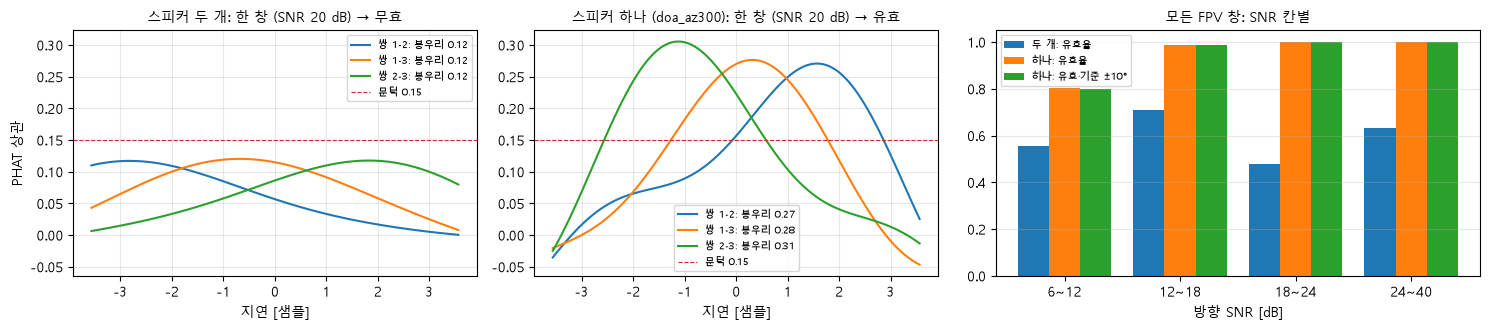

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4), gridspec_kw=dict(width_ratios=[1, 1, 1.2]))
for a, (name, r, w, bg) in zip(ax[:2], [("스피커 두 개", r_sp, w_sp, BG_SP), ("스피커 하나 (" + r_az["folder"] + ")", r_az, w_az, BG_AZ)]):
    S = ds.cross_spectra(w, A.block, 2 * A.block)
    for k, (i_, j_) in enumerate(g.PAIRS):
        t, p, _, lags, cc = g.phat_peak(S[k] - bg[k], 2 * A.block, FS, tuple(A.band), MAX_LAG)
        a.plot(lags, cc, label=f"쌍 {i_ + 1}-{j_ + 1}: 봉우리 {p:.2f}")
    a.axhline(A.min_peak, color="C3", ls="--", lw=.8, label=f"문턱 {A.min_peak}")
    a.set_title(f"{name}: 한 창 (SNR {r['snr']:.0f} dB) → {'유효' if r['valid'] else '무효'}", fontsize=10); a.set_xlabel("지연 [샘플]"); a.grid(alpha=.3); a.legend(fontsize=7)
ax[0].set_ylabel("PHAT 상관"); ax[1].sharey(ax[0])
c = np.arange(len(TAB)); wdt = 0.27
ax[2].bar(c - wdt, [t[3] for t in TAB], wdt, label="두 개: 유효율")
ax[2].bar(c, [t[5] for t in TAB], wdt, label="하나: 유효율")
ax[2].bar(c + wdt, [t[7] for t in TAB], wdt, label="하나: 유효·기준 ±10°")
ax[2].set_xticks(c); ax[2].set_xticklabels([f"{lo}~{hi}" for lo, hi, *_ in TAB]); ax[2].set_xlabel("방향 SNR [dB]"); ax[2].set_ylim(0, 1.05)
ax[2].set_title("모든 FPV 창: SNR 칸별", fontsize=10); ax[2].legend(fontsize=7); ax[2].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

**볼 것:** 같은 SNR에서 두 개는 곡선이 낮고 평평하고(봉우리 < 문턱), 하나는 봉우리가 선다. 오른쪽 — 두 개는 SNR이 높아져도 유효율이 0.5 ~ 0.7에 머문다.

## 그림 B — B0 바닥 (결정: T 측정에서 B0 성공을 어떻게 정할까)

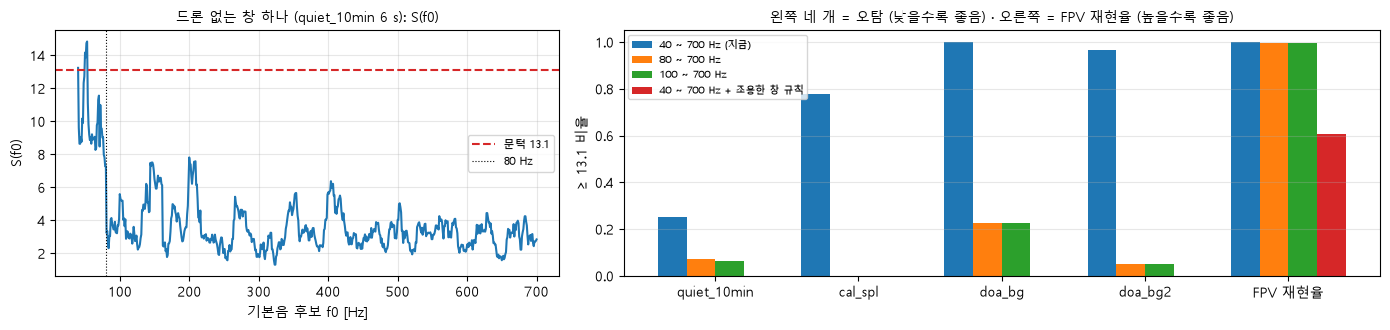

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.4), gridspec_kw=dict(width_ratios=[1, 1.5]))
ax[0].plot(cB, ScB); ax[0].axhline(13.1, color="C3", ls="--", label="문턱 13.1"); ax[0].axvline(80, color="k", lw=.8, ls=":", label="80 Hz")
ax[0].set_title(f"드론 없는 창 하나 (quiet_10min {t0:.0f} s): S(f0)", fontsize=10); ax[0].set_xlabel("기본음 후보 f0 [Hz]"); ax[0].set_ylabel("S(f0)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
x = np.arange(len(names)); wdt = 0.2
for j, (o, row) in enumerate(OPT.items()): ax[1].bar(x + (j - 1.5) * wdt, [row[k] for k in names], wdt, label=o)
ax[1].set_xticks(x); ax[1].set_xticklabels(names); ax[1].set_ylabel("≥ 13.1 비율"); ax[1].set_ylim(0, 1.05)
ax[1].set_title("왼쪽 네 개 = 오탐 (낮을수록 좋음) · 오른쪽 = FPV 재현율 (높을수록 좋음)", fontsize=10); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

**볼 것:** 왼쪽 — 문턱을 넘는 곳이 80 Hz 아래뿐인지. 오른쪽 — 세 가지 대안(80 Hz, 100 Hz, 규칙 켬)이 오탐을 얼마나 줄이고, 대신 FPV 재현율을 얼마나 잃는지 (규칙을 켜면 재현율이 준다).

## 발견

In [10]:
print(f"A: 두 개 유효율 {min(t[3] for t in TAB):.2f} ~ {max(t[3] for t in TAB):.2f}, 하나 {min(t[5] for t in TAB):.2f} ~ {max(t[5] for t in TAB):.2f} (6 dB 이상 칸들)")
print(f"A: 하나의 '정답 ±10°'는 {min(t[6] for t in TAB):.2f} ~ {max(t[6] for t in TAB):.2f}, '기준 ±10°'는 {min(t[7] for t in TAB):.2f} ~ {max(t[7] for t in TAB):.2f} — 폴더 기준 − 폴더 방위 {min(ROT.values())} ~ {max(ROT.values())}°")
print(f"B: 규칙 켬 → 오탐 " + ", ".join(f"{k} {OPT['40 ~ 700 Hz + 조용한 창 규칙'][k]:.2f}" for k in names[:-1]) + f", FPV 재현율 {OPT['40 ~ 700 Hz + 조용한 창 규칙']['FPV 재현율']:.2f}")
print(f"B: 10-27 바닥이 10-16 바닥보다 {dq:+.1f} dB")
bad = [d for d, v in AZ.items() if v["cmax"] < 0.9]
print(f"A2: 재생 시작 상관 < 0.9인 폴더 {[(d, round(AZ[d]['cmax'], 2)) for d in bad]}")
keep = ~np.isin(col(R_AZ, "folder"), bad)
print("   그 폴더를 뺀 하나 유효율: " + ", ".join(f"{lo}~{hi} dB {col(R_AZ, 'valid')[keep & (col(R_AZ, 'snr') >= lo) & (col(R_AZ, 'snr') < hi)].mean():.2f}" for lo, hi in zip(EDGES[:-1], EDGES[1:])))

A: 두 개 유효율 0.48 ~ 0.71, 하나 0.80 ~ 1.00 (6 dB 이상 칸들)
A: 하나의 '정답 ±10°'는 0.23 ~ 0.27, '기준 ±10°'는 0.80 ~ 1.00 — 폴더 기준 − 폴더 방위 8.1 ~ 14.3°
B: 규칙 켬 → 오탐 quiet_10min 0.00, cal_spl 0.00, doa_bg 0.00, doa_bg2 0.00, FPV 재현율 0.61
B: 10-27 바닥이 10-16 바닥보다 -9.7 dB
A2: 재생 시작 상관 < 0.9인 폴더 [('doa_az90', -0.05)]
   그 폴더를 뺀 하나 유효율: 6~12 dB 0.80, 12~18 dB 0.98, 18~24 dB 1.00, 24~40 dB 1.00


- **`doa_az90`은 재생 시작 찾기에 실패했다 (A2 출력, 상관이 다른 폴더의 0.98 이상보다 훨씬 낮음).** 그 폴더의 "FPV 창"은 FPV 구간이 아닐 수 있다. 위 셀은 그 폴더를 뺀 유효율을 같이 낸다. 실패 원인(그 녹음의 재생 내용·시작 시각)은 가리지 않았다.
- **A의 무효 이유가 SNR에 따라 바뀐다 (A6b 출력):** 스피커 두 개는 낮은 SNR에서 닫힘(②)으로, 높은 SNR에서 봉우리(①)로 무효가 된다. 스피커 하나는 낮은 SNR에서만 무효이고 주로 봉우리다.
- **"정답 ±10°"가 낮은 것은 모든 방향에 같이 들어간 회전 때문이다** (위 출력). T 측정은 정답 대신 높은 SNR 기준을 쓰므로 이 회전은 성공 판정에 들어가지 않는다. 회전의 원인(배열 놓은 방향, 채널 지연 보정)은 가리지 않았다.
- **B0 오탐 창의 고조파는 날카로운 48.8·60 Hz 선이 아니라 0 ~ 70 Hz 넓은 저주파 덩어리와 150·210 Hz 근처에 걸린다** (B1 출력). 대화에서 "48.8·60 Hz 선 때문"이라고 했던 것은 틀렸다.
- **Step8b의 "조용함·에어컨 오탐 0 %"는 조용한 창 규칙을 켠 값이다.** 규칙을 켜면 이 노트북에서도 0이 된다 (B3b). Step8d가 규칙을 끈 이유인 "바닥이 바뀌어서"는 10-27 바닥이 10-16보다 약 10 dB 낮은 것이고, 이 차이는 거의 전부 0 ~ 45 Hz에서 생겼다 ([spl_noise.ipynb](spl_noise.ipynb) 4절).
- 녹음마다 바닥이 다른 이유는 가리지 않았다. 10-16 하루에 마이크 전원 RC 필터, ch3 모듈 교체, HSE 전환이 있었고 어느 녹음이 어느 상태였는지 기록이 없다.

## 결론 후보 (사용자 확인 전)

| # | 후보 | 근거 | 아직 모르는 것 |
|---|---|---|---|
| 1 | T 측정 재생은 왼쪽 채널만 있는 파일로 한다 | 그림 A, A4 ~ A6 | 두 녹음은 거리·배경·날짜도 달라, 차이가 전부 스피커 수 때문인지 가를 수 없다 |
| 2 | B0 성공은 후보 아래 끝을 올린 범위로 판정한다 (예: 80 Hz) | 그림 B, B1 · B3 | 13.1을 그 범위에서 다시 정해야 하는지 (Step8b 재계산), 고정익 기본음이 80 Hz 아래로 내려가는 조건 |
| 3 | 40 ~ 700 Hz·규칙 끔을 유지하고, T 측정 날 조용한 창 비율을 같이 기록한다 | 그림 B (`cal_spl` 막대) | 그 비율이 0.5를 넘으면 B0의 50 % 문턱이 정의되지 않는다 |
| 4 | 조용한 창 규칙을 켜되 바닥을 T 측정 날 같은 자리에서 다시 잰다 | 그림 B, B3b | 규칙이 크기(바닥 + 6 dB)로 자르므로 B0의 T가 점수가 아니라 규칙 문턱으로 정해질 수 있다 |